In [5]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("ahemateja19bec1025/traffic-sign-dataset-classification")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'traffic-sign-dataset-classification' dataset.
Path to dataset files: /kaggle/input/traffic-sign-dataset-classification


In [6]:
import os
import glob
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

from sklearn.metrics import confusion_matrix, classification_report
from sklearn.model_selection import train_test_split

import tensorflow as tf

TEST_SIZE=0.1
SEED=1
BATCH_SIZE=128

tf.random.set_seed(SEED)

In [7]:
labels_df = pd.read_csv('/kaggle/input/traffic-sign-dataset-classification/labels.csv')
print(labels_df.sample(10))

#Create a label map
label_map = dict(labels_df.values)

    ClassId                         Name
38       38  Dangerous curve to the left
34       34                 Danger Ahead
53       53                     Give Way
54       54                  No stopping
20       20         Go straight or right
0         0          Speed limit (5km/h)
31       31                        Uturn
49       49                     Unknown5
29       29                         Horn
13       13                Dont Go Right


In [8]:
image_list = list(Path('/kaggle/input/traffic-sign-dataset-classification/traffic_Data/DATA').glob(r'**/*.png'))
labels = list(map(lambda path: os.path.split(os.path.split(path)[0])[1], image_list))

#Create dataframe with path of images and labels
image_series = pd.Series(image_list).astype(str)
labels_series = pd.Series(labels).astype(str)
frame = {'image':image_series, 'label':labels_series}
image_df = pd.DataFrame(frame)
image_df.info()
print(image_df.sample(5))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4170 entries, 0 to 4169
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   image   4170 non-null   object
 1   label   4170 non-null   object
dtypes: object(2)
memory usage: 65.3+ KB
                                                  image label
4116  /kaggle/input/traffic-sign-dataset-classificat...    24
2112  /kaggle/input/traffic-sign-dataset-classificat...    56
1065  /kaggle/input/traffic-sign-dataset-classificat...    42
2796  /kaggle/input/traffic-sign-dataset-classificat...     3
13    /kaggle/input/traffic-sign-dataset-classificat...     7


/tmp/ipykernel_654/1879611874.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=count_labels.index, y=count_labels, palette="rocket")


<Axes: xlabel='label', ylabel='count images'>

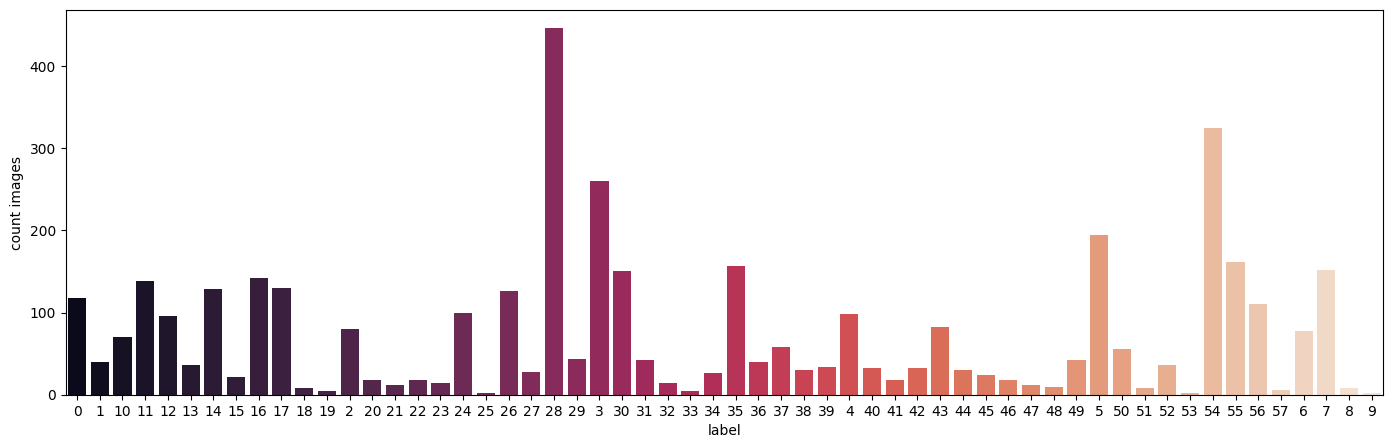

In [9]:
count_labels = image_df.groupby(['label']).size()
plt.figure(figsize=(17,5))
plt.ylabel('count images')
sns.barplot(x=count_labels.index, y=count_labels, palette="rocket")

In [10]:
SPLIT_MINIMUM_COUNT = 10
def split_dataset(df, rate=SPLIT_MINIMUM_COUNT):
  """
  Allocate a  dataset that has at least SPLIT_MINIMUM_COUNT_IMAGES of images
  
  split_df: dataframe for train
  train1_df: dataframe for drop
  """

  count_labels = df.groupby(['label']).size()
  count_labels_df = count_labels.to_frame(name='count_images').reset_index()

  drop_label_list = list(
      count_labels_df['label'].\
      loc[count_labels_df['count_images']<SPLIT_MINIMUM_COUNT]
  )

  drop_df = df.copy()
  split_df = df.copy()

  for index, row in df.iterrows():
    if str(row.label) in drop_label_list:
      split_df = split_df.drop(index)
    else:
      drop_df = drop_df.drop(index)

  return split_df, drop_df

def custom_train_test_split(df):
    """
      Train test split where test_df has minimum 1 image in all labels
    in random split. This need to work model.fit and model.evaluate
    """
  
    labels = df.label.unique()
    test_df = pd.DataFrame()

    for label in labels:
      label_samples = df.loc[df.label==label]
      test_df = pd.concat([test_df, label_samples.sample(len(label_samples)//10+1,
                               random_state=SEED)])
    
    train_df = df.drop(list(test_df.index), axis=0)
    test_df = test_df.sample(frac=1, random_state=SEED)
    train_df = train_df.sample(frac=1, random_state=SEED)

    return train_df, test_df

In [11]:
split_df, _ = split_dataset(image_df)
train_df, test_df = custom_train_test_split(split_df)
train, val = custom_train_test_split(train_df)

In [12]:
train_labels = train_df.groupby(['label']).size()
NUM_CLASSES = len(train_labels)

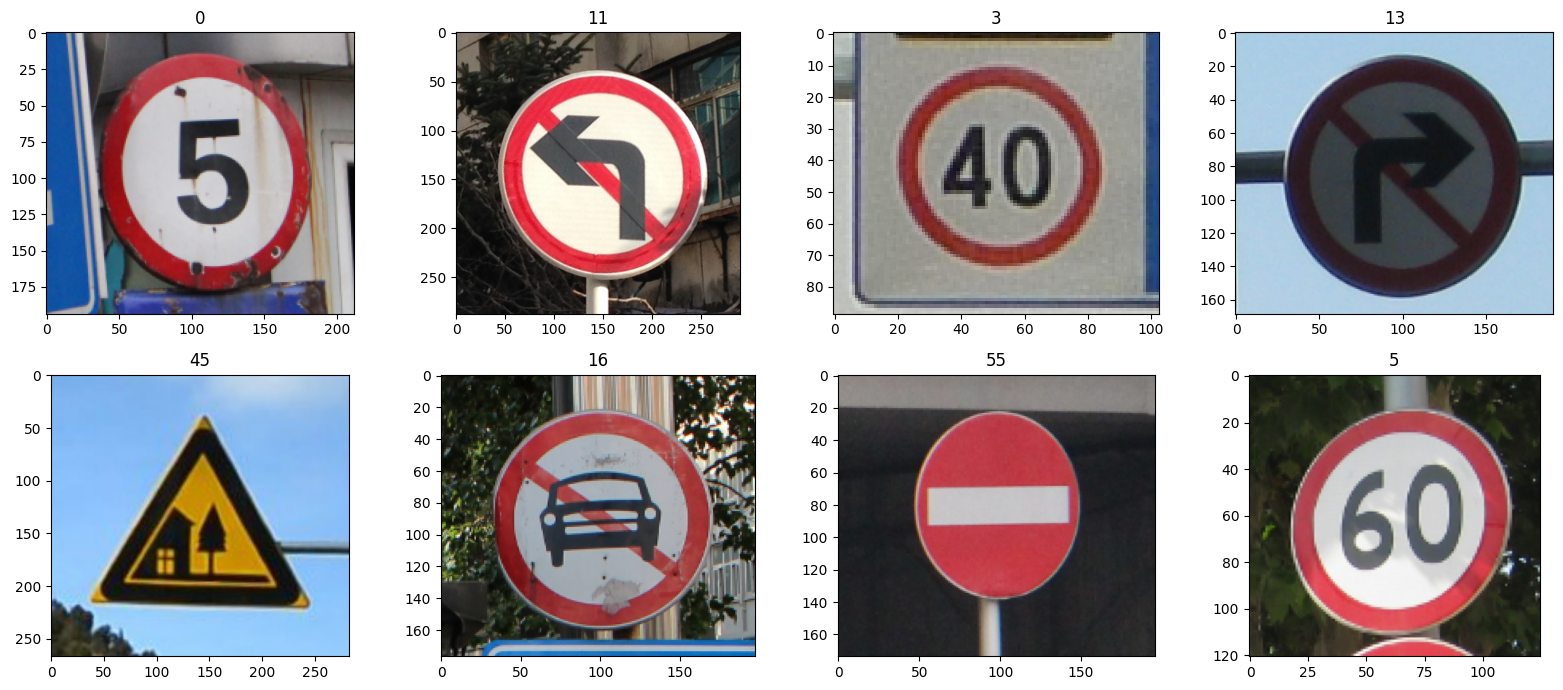

In [13]:
#plot images
fig, axes = plt.subplots(2,4, figsize=(16, 7))
for idx, ax in enumerate(axes.flat):
    ax.imshow(plt.imread(train_df.image.iloc[idx]))
    ax.set_title(train_df.label.iloc[idx])
plt.tight_layout()
plt.show()

In [14]:
train_generator = tf.keras.preprocessing.image.ImageDataGenerator(
    preprocessing_function=tf.keras.applications.efficientnet.preprocess_input,
    rotation_range = 10,
    width_shift_range=0.2,
    height_shift_range=0.2,
    fill_mode='constant',
    shear_range=0.1,
    zoom_range=0.2,
)

test_generator = tf.keras.preprocessing.image.ImageDataGenerator(
    preprocessing_function=tf.keras.applications.efficientnet.preprocess_input,
)

In [15]:
train_images = train_generator.flow_from_dataframe(
    dataframe=train_df,
    x_col='image',
    y_col='label',
    color_mode='rgb',
    class_mode='categorical',
    target_size=(128, 128),
    batch_size=BATCH_SIZE,
    shuffle=True,
    seed=SEED,
)

val_images = test_generator.flow_from_dataframe(
    dataframe=val,
    x_col='image',
    y_col='label',
    color_mode='rgb',
    class_mode='categorical',
    target_size=(128, 128),
    batch_size=BATCH_SIZE,
    shuffle=True,
    seed=SEED,
)


test_images = test_generator.flow_from_dataframe(
    dataframe=test_df,
    x_col='image',
    y_col='label',
    color_mode='rgb',
    class_mode='categorical',
    target_size=(128, 128),
    batch_size=BATCH_SIZE,
)

Found 3683 validated image filenames belonging to 49 classes.
Found 396 validated image filenames belonging to 49 classes.
Found 443 validated image filenames belonging to 49 classes.


In [16]:
#create model
def create_model(input_shape=(128,128,3)):
  """
  load EfficientNet without last layer and 
  add Dense and ouput Dense with NUM_CLASSES units

  """
  inputs = tf.keras.layers.Input(input_shape)

  base_model = tf.keras.applications.EfficientNetB0(
      include_top=False,
      weights='imagenet',
      pooling='avg'
  )
  base_model.trainable = False
  
  x = base_model(inputs)
  x = tf.keras.layers.BatchNormalization()(x)
  x = tf.keras.layers.Dense(512, activation='relu')(x)
  #x = tf.keras.layers.Dropout(0.2)(x)
  #x = tf.keras.layers.Dense(256, activation='relu')(x)
  outputs = tf.keras.layers.Dense(NUM_CLASSES, activation='softmax')(x)

  return tf.keras.models.Model(inputs, outputs)

In [17]:
model = create_model()

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [18]:
model.compile(
    optimizer='Adam',
    loss='categorical_crossentropy',
    metrics=['acc'],
)

In [19]:
callback = tf.keras.callbacks.EarlyStopping(monitor='loss', patience=3, restore_best_weights=True)

history = model.fit(
    train_images,
    epochs=40,
    validation_data=val_images,
    callbacks=[callback]
)

Epoch 1/40
29/29 ━━━━━━━━━━━━━━━━━━━━ 97s 2s/step - acc: 0.6894 - loss: 1.1860 - val_acc: 0.8283 - val_loss: 1.2583
Epoch 2/40
29/29 ━━━━━━━━━━━━━━━━━━━━ 26s 902ms/step - acc: 0.9126 - loss: 0.2921 - val_acc: 0.8990 - val_loss: 0.8494
Epoch 3/40
29/29 ━━━━━━━━━━━━━━━━━━━━ 26s 883ms/step - acc: 0.9422 - loss: 0.1806 - val_acc: 0.9293 - val_loss: 0.6250
Epoch 4/40
29/29 ━━━━━━━━━━━━━━━━━━━━ 26s 891ms/step - acc: 0.9571 - loss: 0.1384 - val_acc: 0.9318 - val_loss: 0.4516
Epoch 5/40
29/29 ━━━━━━━━━━━━━━━━━━━━ 26s 883ms/step - acc: 0.9647 - loss: 0.1016 - val_acc: 0.9394 - val_loss: 0.3295
Epoch 6/40
29/29 ━━━━━━━━━━━━━━━━━━━━ 25s 869ms/step - acc: 0.9750 - loss: 0.0843 - val_acc: 0.9722 - val_loss: 0.2387
Epoch 7/40
29/29 ━━━━━━━━━━━━━━━━━━━━ 25s 871ms/step - acc: 0.9758 - loss: 0.0753 - val_acc: 0.9697 - val_loss: 0.1870
Epoch 8/40
29/29 ━━━━━━━━━━━━━━━━━━━━ 25s 859ms/step - acc: 0.9766 - loss: 0.0714 - val_acc: 0.9672 - val_loss: 0.1577
Epoch 9/40
29/29 ━━━━━━━━━━━━━━━━━━━━ 25s 855ms/ste

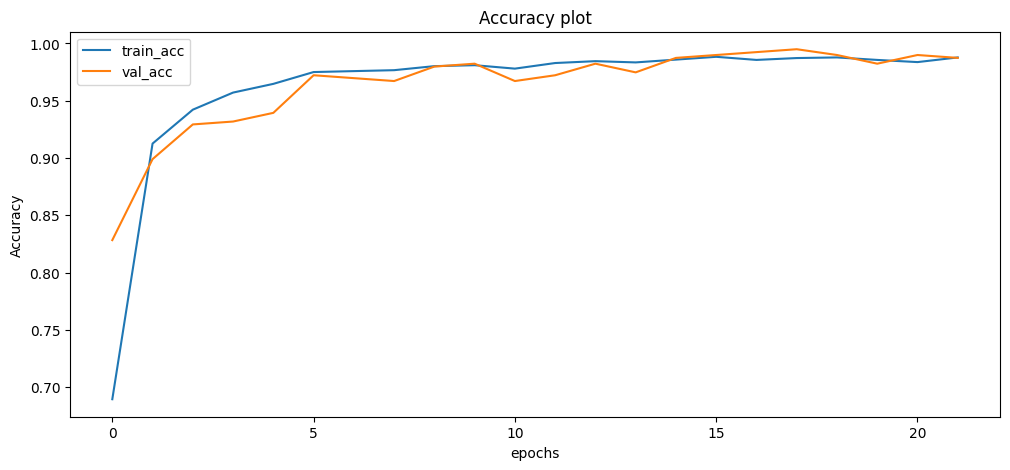

In [20]:
plt.figure(figsize=(12,5))
plt.plot(history.history['acc'], label='train_acc')
plt.plot(history.history['val_acc'], label='val_acc')
plt.title('Accuracy plot')
plt.xlabel('epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

In [21]:
score, accuracy = model.evaluate(test_images)
print(f'Test score: {round(score,4)}, Test accuracy: {round(accuracy,4)}')

4/4 ━━━━━━━━━━━━━━━━━━━━ 10s 3s/step - acc: 0.9842 - loss: 0.0571
Test score: 0.0571, Test accuracy: 0.9842


In [22]:
import joblib

# Save weights
joblib.dump(model.get_weights(), 'model_weights.pkl')

# To load them back later:
# weights = joblib.load('model_weights.pkl')
# model.set_weights(weights)

['model_weights.pkl']

In [23]:
from google.colab import files
files.download('model_weights.pkl')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

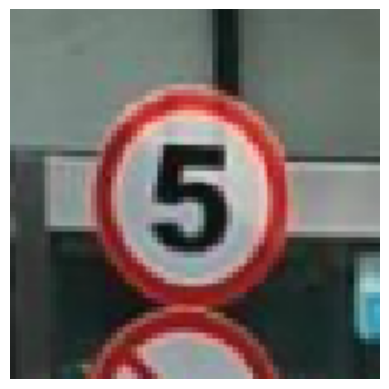

1/1 ━━━━━━━━━━━━━━━━━━━━ 9s 9s/step
The image belongs to class: Speed limit (5km/h)


In [24]:
from tensorflow.keras.preprocessing import image
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

def predict_and_show_image(img_path, model, label_map, target_size=(128, 128)):
    # Step 1: Load and display the image
    img = image.load_img(img_path, target_size=target_size)
    plt.imshow(img)
    plt.axis('off')  # Hide axes
    plt.show()
    
    # Step 2: Preprocess the image for the model
    img_array = image.img_to_array(img)
    img_array = np.expand_dims(img_array, axis=0)
    img_array = tf.keras.applications.efficientnet.preprocess_input(img_array)
    
    # Step 3: Make prediction
    predictions = model.predict(img_array)
    
    # Step 4: Map predicted index to class label
    predicted_class_index = np.argmax(predictions, axis=1)[0]
    predicted_class_label = label_map.get(predicted_class_index)
    
    return predicted_class_label

# Example usage
img_path = '/kaggle/input/traffic-sign-dataset-classification/traffic_Data/TEST/000_0007_j.png'
predicted_class = predict_and_show_image(img_path, model, label_map)
print(f'The image belongs to class: {predicted_class}')
